# Analisis Perbandingan 3 Varian Naive Bayes: Gaussian, Bernoulli, dan Multinomial

Notebook ini membandingkan kinerja algoritma Naive Bayes dengan tiga asumsi distribusi probabilitas berbeda pada **dataset penuh burnout mahasiswa (50.000 baris: 40.000 data latih, 10.000 data uji)** tanpa fitur bocor (`Mental_Health_Status`) serta dengan *preprocessing* bebas *data leakage* (`SimpleImputer` dan *Scaler* di-fit hanya pada data latih / di dalam `Pipeline`):
- **Gaussian Naive Bayes** (`GaussianNB`, fitur kontinu dengan `StandardScaler`)
- **Bernoulli Naive Bayes** (`BernoulliNB`, `StandardScaler` + `binarize=0.0`)
- **Multinomial Naive Bayes** (`MultinomialNB`, fitur non-negatif dengan `MinMaxScaler`)

## 0. Setup

In [11]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)
plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = Path('outputPerbandinganNB')
OUTPUT_DIR.mkdir(exist_ok=True)

TARGET_NAMES = ['Low (0)', 'Moderate (1)', 'High (2)']
VARIANTS = ['Gaussian', 'Bernoulli', 'Multinomial']
COLORS = ['#2b5c8f', '#e74c3c', '#8e44ad']

## 1. Menentukan File Sumber Data dan Output Model

In [12]:
DIRS = {
    'Gaussian': Path('outputNBAntiBurnoutGaussian'),
    'Bernoulli': Path('outputNBAntiBurnoutBernoulli'),
    'Multinomial': Path('outputNBAntiBurnoutMultinomial')
}

FILES = {
    'Gaussian': {
        'metrics': DIRS['Gaussian'] / 'metrics_nb_gaussian.csv',
        'preds': DIRS['Gaussian'] / 'predictions_nb_gaussian.csv',
        'cv': DIRS['Gaussian'] / 'cv_5fold_nb_gaussian.csv'
    },
    'Bernoulli': {
        'metrics': DIRS['Bernoulli'] / 'metrics_nb_bernoulli.csv',
        'preds': DIRS['Bernoulli'] / 'predictions_nb_bernoulli.csv',
        'cv': DIRS['Bernoulli'] / 'cv_5fold_nb_bernoulli.csv'
    },
    'Multinomial': {
        'metrics': DIRS['Multinomial'] / 'metrics_nb_multinomial.csv',
        'preds': DIRS['Multinomial'] / 'predictions_nb_multinomial.csv',
        'cv': DIRS['Multinomial'] / 'cv_5fold_nb_multinomial.csv'
    }
}

for v in VARIANTS:
    print(f'Direktori sumber {v}: {DIRS[v].resolve()}')

Direktori sumber Gaussian: D:\My Files\File Penting\MACHINE_LEARNING_PBL_REPO\MachineLearningPBL\NaiveBayes\outputNBAntiBurnoutGaussian
Direktori sumber Bernoulli: D:\My Files\File Penting\MACHINE_LEARNING_PBL_REPO\MachineLearningPBL\NaiveBayes\outputNBAntiBurnoutBernoulli
Direktori sumber Multinomial: D:\My Files\File Penting\MACHINE_LEARNING_PBL_REPO\MachineLearningPBL\NaiveBayes\outputNBAntiBurnoutMultinomial


## 2. Memuat Hasil Evaluasi Ketiga Varian Naive Bayes

In [13]:
metrics_list = []
for v in VARIANTS:
    df_v = pd.read_csv(FILES[v]['metrics'])
    metrics_list.append(df_v)

df_comparison_nb = pd.concat(metrics_list, ignore_index=True)
df_comparison_nb

,Model,Distribusi,Var_Smoothing,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB,Alpha,Binarize,Scaler
0,Naive Bayes (GaussianNB),Gaussian,1.000000e-09,0.7954,0.7885,0.7494,0.7624,0.7851,0.7909,0.7571,0.0312,9.4234,NaN,NaN,NaN
1,Naive Bayes (BernoulliNB),Bernoulli,NaN,0.7774,0.7415,0.7622,0.7494,0.7795,0.7761,0.7472,0.0469,11.6339,1.0,0.0,NaN
2,Naive Bayes (MultinomialNB),Multinomial,NaN,0.8063,0.8167,0.7702,0.7826,0.8087,0.8050,0.7800,0.0312,2.4788,1.0,NaN,MinMaxScaler


## 3. Perbandingan Distribusi Kelas Prediksi vs Aktual

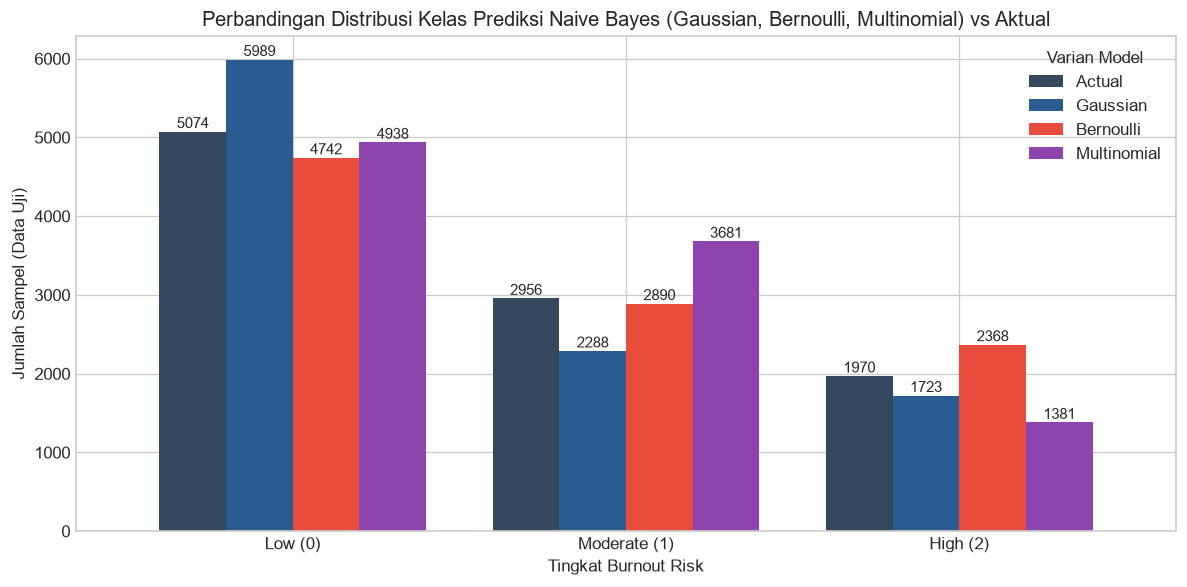

,Actual,Gaussian,Bernoulli,Multinomial
Low (0),5074,5989,4742,4938
Moderate (1),2956,2288,2890,3681
High (2),1970,1723,2368,1381


In [14]:
preds_dict_nb = {v: pd.read_csv(FILES[v]['preds']) for v in VARIANTS}
y_actual_nb = preds_dict_nb['Gaussian']['Actual']

dist_data_nb = {
    'Actual': y_actual_nb.value_counts().sort_index().values
}
for v in VARIANTS:
    dist_data_nb[v] = preds_dict_nb[v]['Predicted'].value_counts().reindex([0, 1, 2], fill_value=0).sort_index().values

df_dist_nb = pd.DataFrame(dist_data_nb, index=TARGET_NAMES)

ax = df_dist_nb.plot(
    kind='bar',
    figsize=(10, 5),
    color=['#34495e', '#2b5c8f', '#e74c3c', '#8e44ad'],
    width=0.8
)
plt.title('Perbandingan Distribusi Kelas Prediksi Naive Bayes (Gaussian, Bernoulli, Multinomial) vs Aktual')
plt.xlabel('Tingkat Burnout Risk')
plt.ylabel('Jumlah Sampel (Data Uji)')
plt.xticks(rotation=0)
plt.legend(title='Varian Model')
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2., p.get_height() + 5), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_distribusi_nb.png')
plt.show()

df_dist_nb

## 4. Perbandingan Confusion Matrix Ketiga Varian Berdampingan

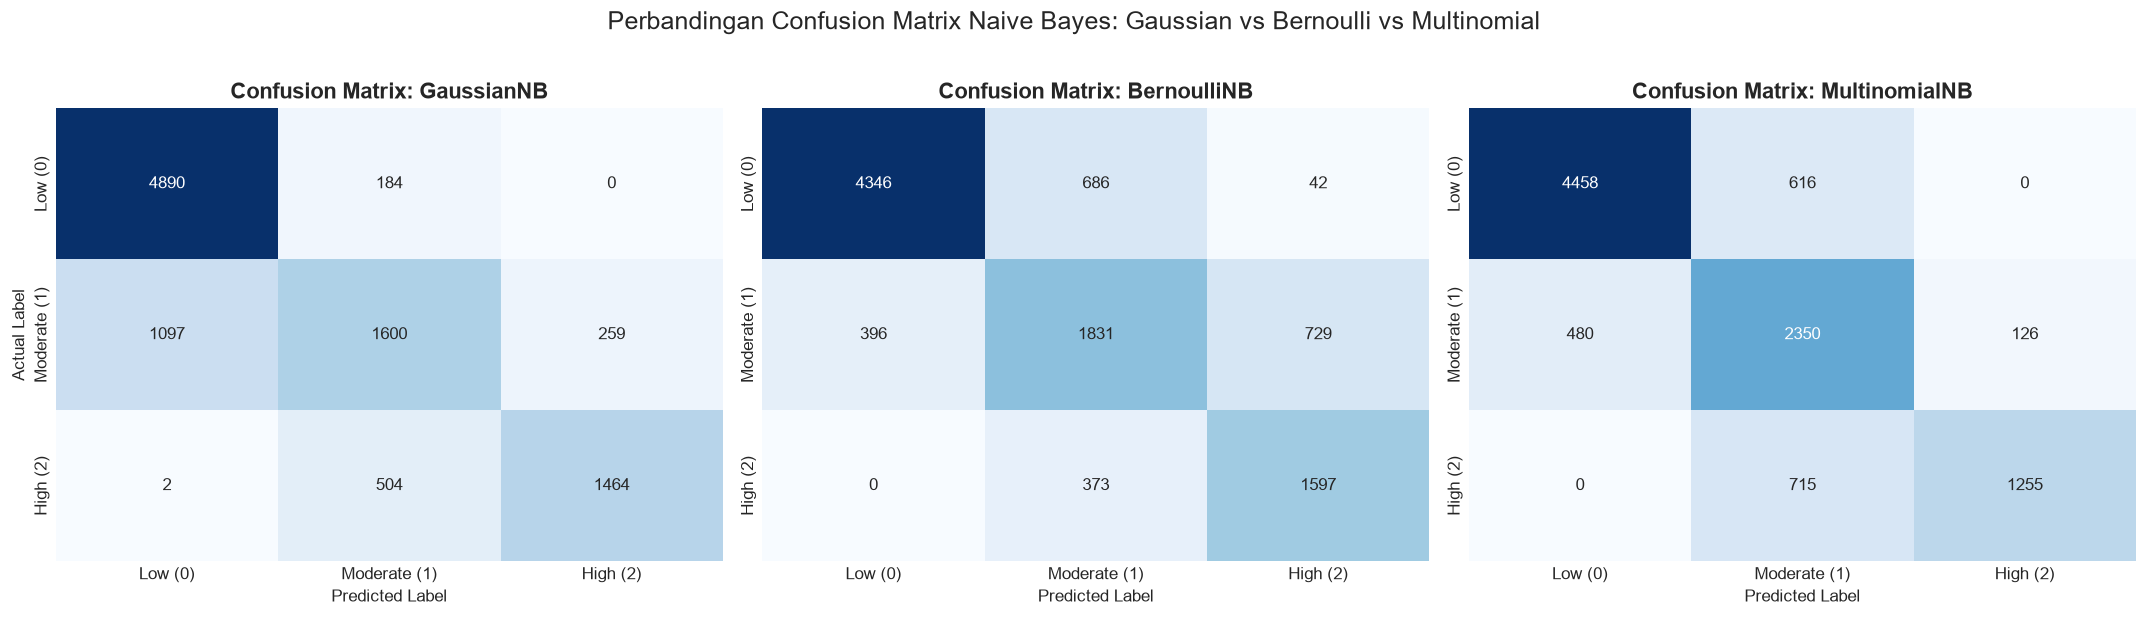

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, v in enumerate(VARIANTS):
    cm = confusion_matrix(y_actual_nb, preds_dict_nb[v]['Predicted'])
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=TARGET_NAMES,
        yticklabels=TARGET_NAMES,
        ax=axes[i],
        cbar=False
    )
    axes[i].set_title(f'Confusion Matrix: {v}NB', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label' if i == 0 else '')

plt.suptitle('Perbandingan Confusion Matrix Naive Bayes: Gaussian vs Bernoulli vs Multinomial', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_confusion_matrix_nb.png')
plt.show()

## 5. Diagram Perbandingan Kuantitatif Metrik Kinerja Data Uji

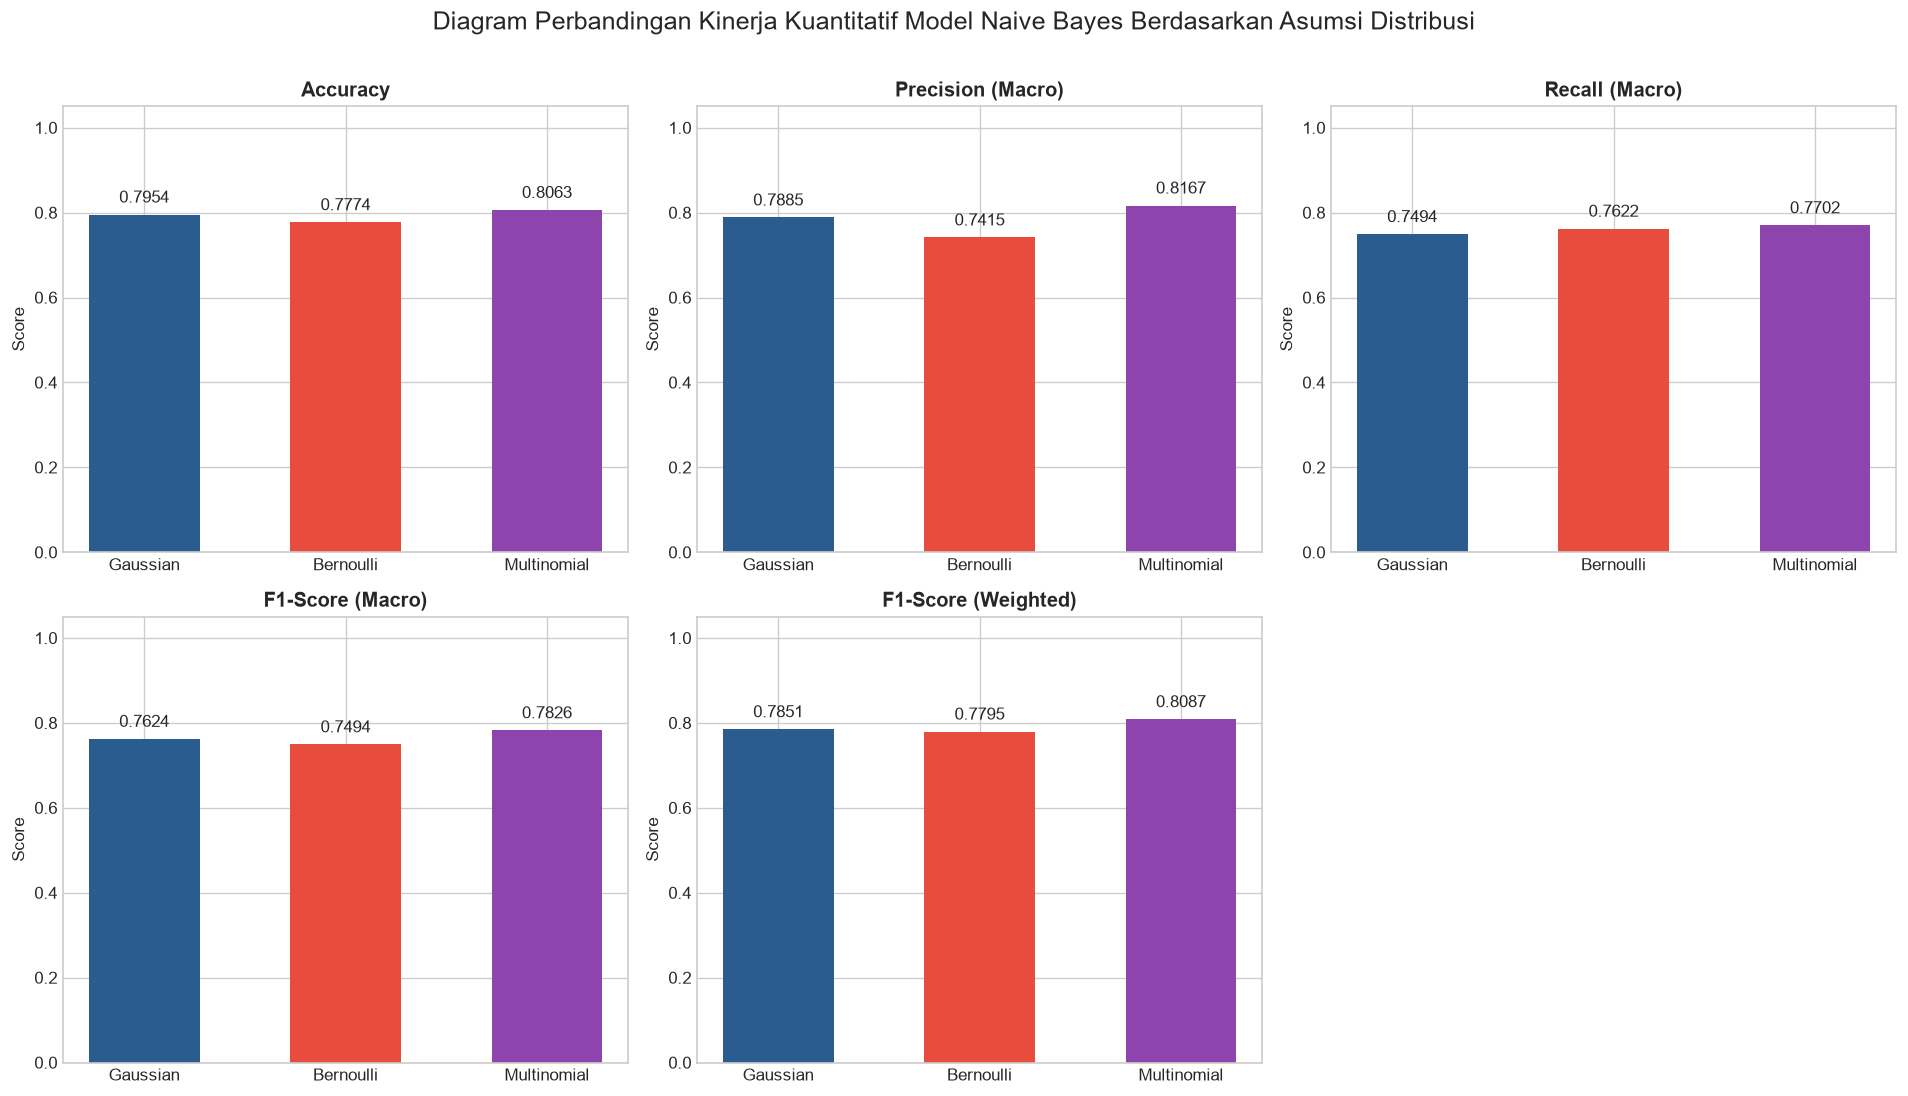

In [16]:
metrics_cols = ['Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Score_Macro', 'F1_Score_Weighted']
metric_labels = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)', 'F1-Score (Weighted)']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes_flat = axes.flatten()

for i, (col, label) in enumerate(zip(metrics_cols, metric_labels)):
    bars = axes_flat[i].bar(
        df_comparison_nb['Distribusi'],
        df_comparison_nb[col],
        color=COLORS,
        width=0.55
    )
    axes_flat[i].set_title(label, fontsize=12, fontweight='bold')
    axes_flat[i].set_ylim(0, 1.05)
    axes_flat[i].set_ylabel('Score')
    for bar in bars:
        h = bar.get_height()
        axes_flat[i].text(bar.get_x() + bar.get_width() / 2., h + 0.02, f'{h:.4f}', ha='center', va='bottom', fontsize=10)

axes_flat[5].axis('off')

plt.suptitle('Diagram Perbandingan Kinerja Kuantitatif Model Naive Bayes Berdasarkan Asumsi Distribusi', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_metrik_evaluasi_nb.png')
plt.show()

## 6. Perbandingan Hasil Stratified 5-Fold Cross-Validation

,Gaussian_Accuracy,Bernoulli_Accuracy,Multinomial_Accuracy,Gaussian_F1_Macro,Bernoulli_F1_Macro,Multinomial_F1_Macro
Fold 1,0.7904,0.7713,0.8061,0.756587,0.740915,0.780846
Fold 2,0.7904,0.7850,0.8078,0.756755,0.758212,0.783373
Fold 3,0.7904,0.7766,0.8053,0.756481,0.747585,0.779806
Fold 4,0.7906,0.7739,0.8019,0.757085,0.744847,0.777027
Fold 5,0.7928,0.7737,0.8039,0.758818,0.744253,0.778774


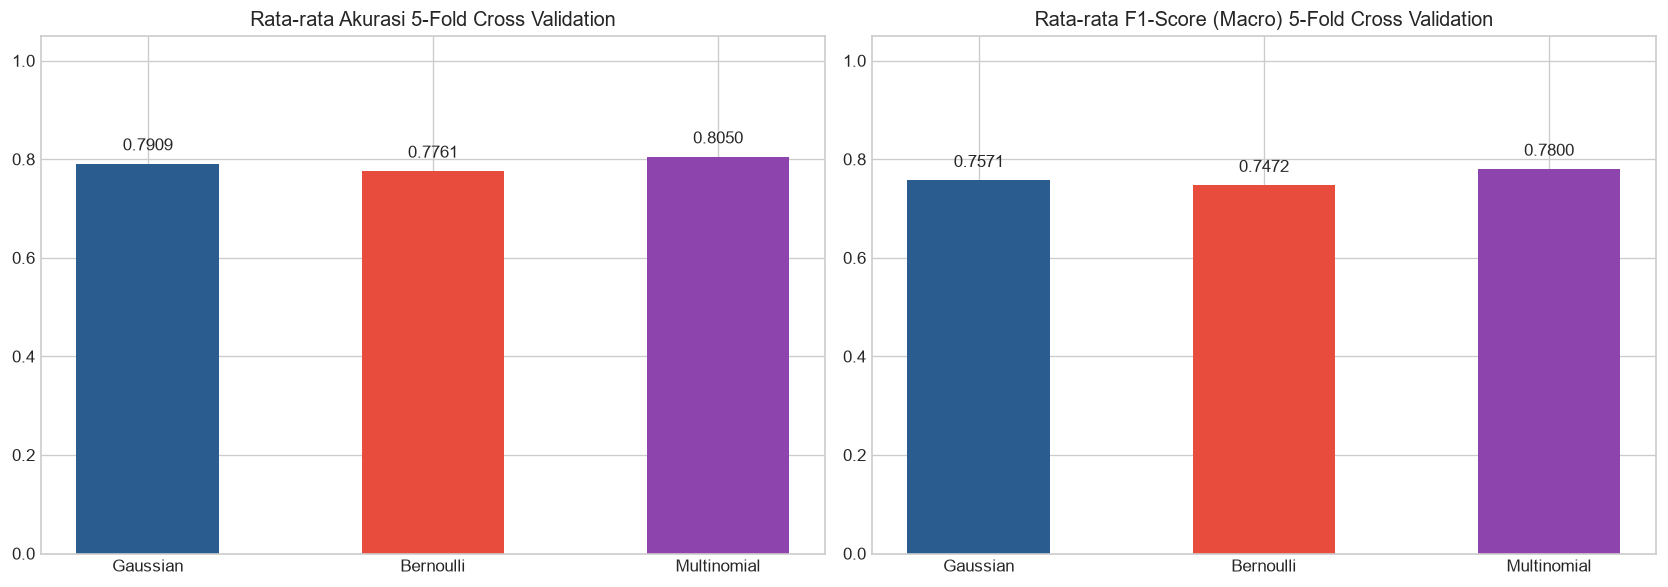

In [17]:
cv_dfs_nb = {v: pd.read_csv(FILES[v]['cv']) for v in VARIANTS}

cv_folds_nb = pd.DataFrame({
    f'{v}_Accuracy': cv_dfs_nb[v].iloc[:5]['Accuracy'].values
    for v in VARIANTS
}, index=[f'Fold {i+1}' for i in range(5)])

cv_folds_nb_f1 = pd.DataFrame({
    f'{v}_F1_Macro': cv_dfs_nb[v].iloc[:5]['F1-Score (Macro)'].values
    for v in VARIANTS
}, index=[f'Fold {i+1}' for i in range(5)])

display(pd.concat([cv_folds_nb, cv_folds_nb_f1], axis=1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cv_acc_means_nb = [df_comparison_nb.loc[df_comparison_nb['Distribusi'] == v, 'CV_5Fold_Accuracy_Mean'].values[0] for v in VARIANTS]
cv_f1_means_nb = [df_comparison_nb.loc[df_comparison_nb['Distribusi'] == v, 'CV_5Fold_F1_Macro_Mean'].values[0] for v in VARIANTS]

bars1 = axes[0].bar(VARIANTS, cv_acc_means_nb, color=COLORS, width=0.5)
axes[0].set_title('Rata-rata Akurasi 5-Fold Cross Validation')
axes[0].set_ylim(0, 1.05)
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2., h + 0.02, f'{h:.4f}', ha='center', va='bottom')

bars2 = axes[1].bar(VARIANTS, cv_f1_means_nb, color=COLORS, width=0.5)
axes[1].set_title('Rata-rata F1-Score (Macro) 5-Fold Cross Validation')
axes[1].set_ylim(0, 1.05)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2., h + 0.02, f'{h:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_cv_nb.png')
plt.show()

## 7. Perbandingan Efisiensi Komputasi (Waktu dan Memori)

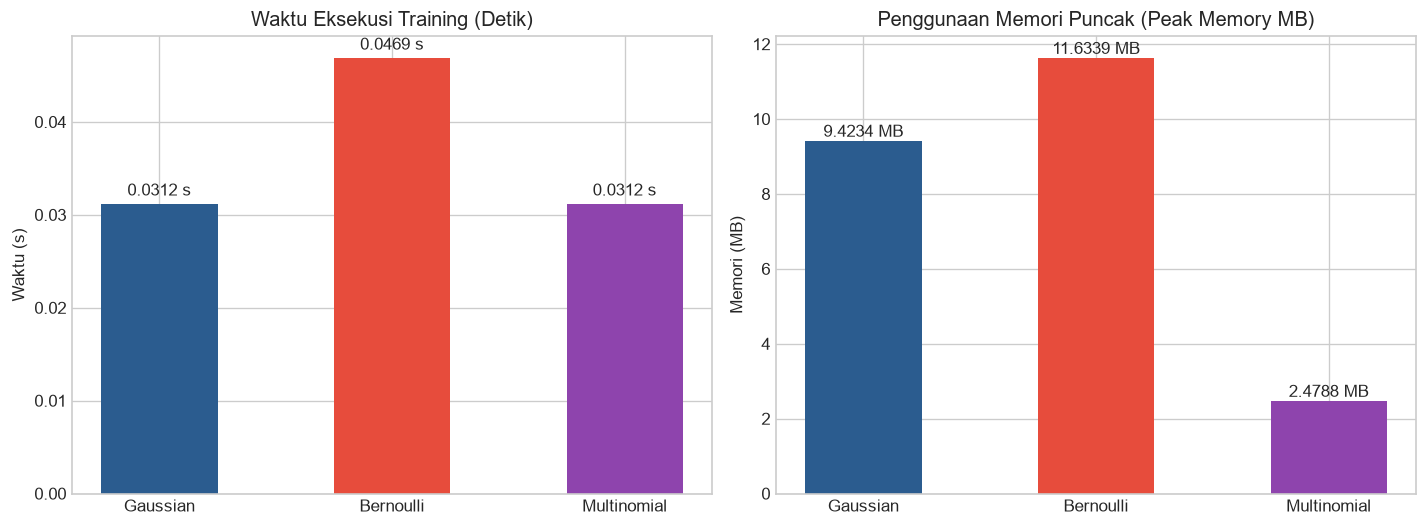

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars1 = axes[0].bar(df_comparison_nb['Distribusi'], df_comparison_nb['Training_Time_s'], color=COLORS, width=0.5)
axes[0].set_title('Waktu Eksekusi Training (Detik)')
axes[0].set_ylabel('Waktu (s)')
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2., h + 0.0005, f'{h:.4f} s', ha='center', va='bottom')

bars2 = axes[1].bar(df_comparison_nb['Distribusi'], df_comparison_nb['Peak_Memory_MB'], color=COLORS, width=0.5)
axes[1].set_title('Penggunaan Memori Puncak (Peak Memory MB)')
axes[1].set_ylabel('Memori (MB)')
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2., h + 0.01, f'{h:.4f} MB', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_efisiensi_nb.png')
plt.show()

## 8. Tabel Hasil Akhir Komparasi Model Naive Bayes

In [19]:
tabel_ringkasan_nb = df_comparison_nb[[
    'Model', 'Distribusi', 'Accuracy', 
    'Precision_Macro', 'Recall_Macro', 'F1_Score_Macro', 'F1_Score_Weighted',
    'CV_5Fold_Accuracy_Mean', 'CV_5Fold_F1_Macro_Mean', 'Training_Time_s', 'Peak_Memory_MB'
]].copy()

tabel_ringkasan_nb

,Model,Distribusi,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,Naive Bayes (GaussianNB),Gaussian,0.7954,0.7885,0.7494,0.7624,0.7851,0.7909,0.7571,0.0312,9.4234
1,Naive Bayes (BernoulliNB),Bernoulli,0.7774,0.7415,0.7622,0.7494,0.7795,0.7761,0.7472,0.0469,11.6339
2,Naive Bayes (MultinomialNB),Multinomial,0.8063,0.8167,0.7702,0.7826,0.8087,0.8050,0.7800,0.0312,2.4788


## 9. Kesimpulan dan Rekomendasi Varian Terbaik

### Analisis Detail per Aspek Evaluasi (50.000 Sampel, Bebas Target & Preprocessing Leakage):
- **Distribusi Prediksi & Confusion Matrix (10.000 Data Uji: Low=5.074, Moderate=2.956, High=1.970):**
  - **MultinomialNB** mencatat **0 kesalahan ekstrem (`Low` ↔ `High`)**, serta paling baik mengenali kelas tengah `Moderate` (**2.350** dari 2.956 benar), dengan total prediksi `Low=4.938`, `Moderate=3.681`, `High=1.381`.
  - **GaussianNB** kuat pada kelas mayoritas `Low` (**4.890** benar), tetapi mengalami bias berlebih ke `Low` (memprediksi **5.989** sampel sebagai `Low` sehingga **1.097** sampel `Moderate` turun menjadi `Low`) dan mencatat **2 kesalahan ekstrem** (`High` diprediksi `Low`).
  - **BernoulliNB** memprediksi lebih banyak kelas `High` (**2.368** prediksi vs 1.970 aktual) dan memicu **42 kesalahan ekstrem** (`Low` diprediksi `High`).
- **Kinerja Data Uji & Stratified 5-Fold Cross-Validation:**
  - **MultinomialNB** unggul di seluruh metrik utama: Accuracy **80.63%**, Precision (Macro) **81.67%**, Recall (Macro) **77.02%**, F1-Score (Macro) **78.26%**, F1-Score (Weighted) **80.87%**, serta 5-Fold CV Accuracy Mean **80.50% (±0.20%)** dan CV F1-Macro **78.00% (±0.21%)**.
  - **GaussianNB** di peringkat kedua dengan Accuracy **79.54%**, F1-Score (Macro) **76.24%**, dan 5-Fold CV Accuracy Mean **79.09% (±0.09%)**.
  - **BernoulliNB** di peringkat ketiga dengan Accuracy **77.74%**, F1-Score (Macro) **74.94%**, dan 5-Fold CV Accuracy Mean **77.61% (±0.48%)**.
- **Efisiensi Komputasi (Waktu & Memori):**
  - **MultinomialNB** dan **GaussianNB** sama-sama mencatat waktu latih tercepat (**0.0312 s**), diikuti **BernoulliNB** (**0.0469 s**).
  - Dari sisi memori puncak, **MultinomialNB** paling hemat (**2.4788 MB**), jauh lebih rendah dibanding **GaussianNB** (**9.4234 MB**) dan **BernoulliNB** (**11.6339 MB**).

### Kesimpulan Tiap Varian:
1. **Multinomial Naive Bayes (`MultinomialNB`) — Varian Terbaik (Peringkat 1):**
   - Unggul secara menyeluruh pada akurasi (80.63%), F1-Macro (78.26%), stabilitas 5-Fold CV (80.50%), efisiensi memori (2.4788 MB), dan **0 kesalahan ekstrem**.
   - **Alasan Ilmiah:** Setelah kolom `Mental_Health_Status` dihapus untuk mencegah *data leakage*, dataset terdiri atas campuran fitur kontinu dan fitur ordinal/biner (`Sleep_Quality`, `Stress_Level`, `Exercise_Frequency`, `Support_System`, dll.). Penskalakan `MinMaxScaler` ke rentang `[0, 1]` memungkinkan `MultinomialNB` menimbang kontribusi proporsional tiap fitur tanpa memaksakan asumsi kurva normal.

2. **Gaussian Naive Bayes (`GaussianNB`) — Peringkat 2:**
   - Stabil antar-fold (±0.09%) dan cepat dilatih (0.0312 s), namun bias ke kelas `Low` menurunkan recall kelas `Moderate` (1.600/2.956 benar) karena fitur bertipe ordinal/biner tidak sepenuhnya mengikuti distribusi normal kontinu murni.

3. **Bernoulli Naive Bayes (`BernoulliNB`) — Peringkat 3:**
   - Binerisasi ambang batas (`binarize=0.0`) menghilangkan gradasi intensitas fitur numerik maupun ordinal bertingkat, sehingga menghasilkan akurasi terendah (77.74%), memori terbesar (11.6339 MB), dan 42 kesalahan ekstrem (`Low` → `High`).

### Rekomendasi Akhir:
Untuk klasifikasi risiko burnout menggunakan keluarga algoritma Naive Bayes pada dataset penuh bebas kebocoran data, **Multinomial Naive Bayes (`MultinomialNB` + `MinMaxScaler`)** adalah varian yang paling direkomendasikan karena unggul di seluruh metrik akurasi, F1-Score, efisiensi memori, serta memiliki nol kesalahan ekstrem antar kelas risiko berlawanan.

## 10. Ekspor Hasil Perbandingan

In [20]:
df_comparison_nb.to_csv(OUTPUT_DIR / 'perbandingan_varian_nb.csv', index=False)
df_dist_nb.to_csv(OUTPUT_DIR / 'perbandingan_distribusi_nb.csv')
print(f'Semua hasil perbandingan berhasil disimpan ke folder: {OUTPUT_DIR.resolve()}')
for p in sorted(OUTPUT_DIR.glob('*')):
    print('-', p.name)

Semua hasil perbandingan berhasil disimpan ke folder: D:\My Files\File Penting\MACHINE_LEARNING_PBL_REPO\MachineLearningPBL\NaiveBayes\outputPerbandinganNB
- perbandingan_confusion_matrix_nb.png
- perbandingan_cv_nb.png
- perbandingan_distribusi_nb.csv
- perbandingan_distribusi_nb.png
- perbandingan_efisiensi_nb.png
- perbandingan_metrik_evaluasi_nb.png
- perbandingan_varian_nb.csv
